# Normalizing Flow on a Ring of Gaussians

This notebook implements a **normalizing flow** from first principles in PyTorch on the same two-dimensional ring-of-Gaussians example used for the VAE.

### Learning goals
1. Explain exact density evaluation through change of variables.
2. Understand affine coupling layers and their triangular Jacobian.
3. Implement forward (data-to-base) and inverse (base-to-data) transformations.
4. Train by exact maximum likelihood, without an ELBO or discriminator.
5. Visualize how a simple Gaussian is warped into a multimodal density.

Because both spaces are 2D, the density and transformation can be inspected directly.

## Before you begin

**Prerequisites.** You should be comfortable with multivariate densities, Jacobians and determinants, the change-of-variables formula, neural networks, and PyTorch automatic differentiation. No previous flow implementation is assumed.

> **Notation and orientation**
> - $x\in\mathbb R^2$ is a data point and $z\in\mathbb R^2$ is a base-space point with $p_Z=\mathcal N(0,I)$.
> - The notebook defines **forward** as data-to-base, $z=f_\theta(x)$, and **inverse** as base-to-data, $x=f_\theta^{-1}(z)$.
> - Log-density accumulates a base-density term plus $\log|\det J|$. Sampling reverses the same invertible map.

## 1. Setup

Only NumPy, Matplotlib, and PyTorch are required. Training uses a GPU automatically when available.

**Runtime:** This toy model trains directly in the notebook. Expect roughly tens of seconds on a recent GPU and up to a few minutes on CPU. The exact time depends on your hardware.


In [1]:
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (6, 5), "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.12.0+cu130 | device: cuda


## 2. Data: a ring of Gaussians

We use an equally weighted mixture of $K$ isotropic Gaussian components:

$$\mu_k=r[\cos(2\pi k/K),\sin(2\pi k/K)]^\top,\qquad
x\mid k\sim\mathcal N(\mu_k,\sigma_{data}^2I).$$

Component labels are retained only for visualization. Density estimation is unsupervised.

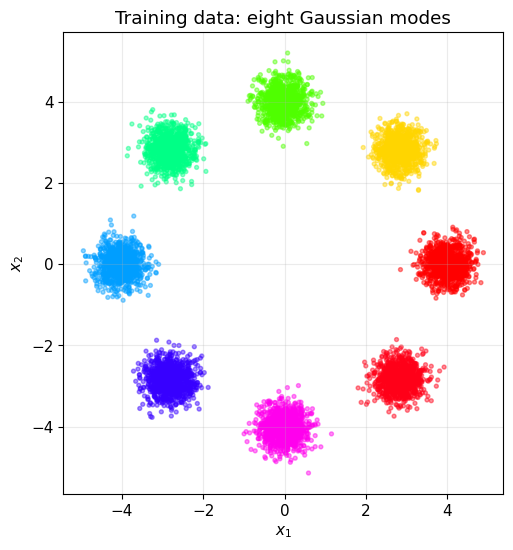

Train shape: (8000, 2)


In [2]:
def sample_ring(n_samples, n_modes=8, radius=4.0, std=0.30, seed=0):
    """Return observations and visualization-only component labels."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.randint(n_modes, (n_samples,), generator=g)
    angles = 2 * torch.pi * labels.float() / n_modes
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n_samples, 2, generator=g), labels


N_MODES, RADIUS, DATA_STD = 8, 4.0, 0.30
x_train, y_train = sample_ring(8_000, N_MODES, RADIUS, DATA_STD, SEED)
x_test, y_test = sample_ring(2_000, N_MODES, RADIUS, DATA_STD, SEED + 1)
train_loader = DataLoader(
    TensorDataset(x_train),
    batch_size=512,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap="hsv", s=8, alpha=0.45)
ax.set(title="Training data: eight Gaussian modes", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal")
plt.show()
print("Train shape:", tuple(x_train.shape))

## 3. Change of variables

A normalizing flow is an invertible map $f_\theta$ between data $x$ and a simple base variable $z$:

$$z=f_\theta(x),\qquad x=f_\theta^{-1}(z),\qquad z\sim p_Z(z)=\mathcal N(0,I).$$

The change-of-variables formula gives an **exact normalized density**:

$$\log p_X(x)=\log p_Z(f_\theta(x))+\log\left|\det\frac{\partial f_\theta(x)}{\partial x}\right|.$$

Training minimizes exact negative log likelihood. Sampling runs the same transformation in reverse.

### What makes flow design difficult?

A useful layer must simultaneously be:
- expressive,
- invertible,
- efficient in both directions, and
- equipped with a cheap Jacobian determinant.

Affine coupling layers satisfy these requirements.

## 4. Affine coupling layers (RealNVP)

Split $x$ into an unchanged part $x_a$ and transformed part $x_b$:

$$z_a=x_a,\qquad z_b=x_b\odot\exp(s_\theta(x_a))+t_\theta(x_a).$$

The inverse is explicit:

$$x_a=z_a,\qquad x_b=(z_b-t_\theta(z_a))\odot\exp(-s_\theta(z_a)).$$

The Jacobian is triangular, so

$$\log|\det J|=\sum_j s_{\theta,j}(x_a).$$

A binary mask chooses the unchanged coordinates. Alternating masks ensures every coordinate is transformed. We bound the log-scale with `tanh` for stable optimization.

In [3]:
class Conditioner(nn.Module):
    """Small network producing translation and bounded log-scale."""

    def __init__(self, dim=2, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2 * dim),
        )
        # Start each coupling transform close to the identity.
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, x):
        shift, raw_log_scale = self.net(x).chunk(2, dim=-1)
        return shift, 1.8 * torch.tanh(raw_log_scale / 1.8)


class AffineCoupling(nn.Module):
    def __init__(self, mask, hidden=64):
        super().__init__()
        self.register_buffer("mask", torch.tensor(mask, dtype=torch.float32))
        self.conditioner = Conditioner(dim=len(mask), hidden=hidden)

    def forward(self, x):
        """Data -> base; return transformed values and log|det J|."""
        masked = x * self.mask
        shift, log_scale = self.conditioner(masked)
        inverse_mask = 1 - self.mask
        z = masked + inverse_mask * (x * torch.exp(log_scale) + shift)
        log_det = (inverse_mask * log_scale).sum(dim=-1)
        return z, log_det

    def inverse(self, z):
        """Base -> data."""
        masked = z * self.mask
        shift, log_scale = self.conditioner(masked)
        inverse_mask = 1 - self.mask
        return masked + inverse_mask * (z - shift) * torch.exp(-log_scale)


class RealNVP(nn.Module):
    def __init__(self, n_layers=12, hidden=64):
        super().__init__()
        masks = [[1.0, 0.0] if i % 2 == 0 else [0.0, 1.0] for i in range(n_layers)]
        self.layers = nn.ModuleList([AffineCoupling(mask, hidden) for mask in masks])
        self.register_buffer(
            "log_2pi", torch.tensor(np.log(2 * np.pi), dtype=torch.float32)
        )

    def forward(self, x):
        z, total_log_det = x, torch.zeros(len(x), device=x.device)
        for layer in self.layers:
            z, log_det = layer(z)
            total_log_det += log_det
        return z, total_log_det

    def inverse(self, z):
        x = z
        for layer in reversed(self.layers):
            x = layer.inverse(x)
        return x

    def log_prob(self, x):
        z, log_det = self.forward(x)
        base_log_prob = -0.5 * (z.square() + self.log_2pi).sum(dim=-1)
        return base_log_prob + log_det

    @torch.no_grad()
    def sample(self, n):
        return self.inverse(torch.randn(n, 2, device=self.log_2pi.device))


flow = RealNVP().to(DEVICE)
print(flow)
print(f"Parameters: {sum(p.numel() for p in flow.parameters()):,}")

RealNVP(
  (layers): ModuleList(
    (0-11): 12 x AffineCoupling(
      (conditioner): Conditioner(
        (net): Sequential(
          (0): Linear(in_features=2, out_features=64, bias=True)
          (1): ReLU()
          (2): Linear(in_features=64, out_features=64, bias=True)
          (3): ReLU()
          (4): Linear(in_features=64, out_features=4, bias=True)
        )
      )
    )
  )
)
Parameters: 55,344


## 5. Verify invertibility and the Jacobian

Before training, we will test two defining properties:

1. $f_\theta^{-1}(f_\theta(x))\approx x$ numerically.
2. The analytic log determinant agrees with one obtained using automatic differentiation.

These checks are especially valuable when implementing a new flow transformation.

> **Predict before running.** What numerical reconstruction error should $f_\theta^{-1}(f_\theta(x))-x$ have, and should the analytic and autograd log-determinants agree in sign as well as magnitude? **Record your prediction and justify it from the affine-coupling inverse.**

In [4]:
probe = torch.tensor([[1.2, -0.7], [-2.0, 3.1]], device=DEVICE)
z_probe, log_det = flow(probe)
recovered = flow.inverse(z_probe)
round_trip_error = (probe - recovered).abs().max()

# Compare the analytic determinant with autograd for one observation.
x_one = probe[:1].clone().requires_grad_(True)


def one_forward(v):
    return flow(v.unsqueeze(0))[0].squeeze(0)


jacobian = torch.autograd.functional.jacobian(one_forward, x_one.squeeze(0))
autograd_log_det = torch.linalg.slogdet(jacobian).logabsdet
analytic_log_det = flow(x_one)[1].squeeze()

print(f"Maximum round-trip error: {round_trip_error.item():.2e}")
print(f"Analytic log|det J|: {analytic_log_det.item():.6f}")
print(f"Autograd log|det J|: {autograd_log_det.item():.6f}")
assert round_trip_error < 1e-5
assert torch.allclose(analytic_log_det, autograd_log_det, atol=1e-5)

Maximum round-trip error: 0.00e+00
Analytic log|det J|: 0.000000
Autograd log|det J|: 0.000000


> **Expected observation / interpretation.** Round-trip errors should be near floating-point precision, and both log-determinant calculations should agree. This is a structural correctness check: a model can optimize a loss while still having an incorrect inverse or Jacobian bookkeeping.

## 6. Train by maximum likelihood

There is no variational bound: we directly minimize

$$\mathcal L(\theta)=-\frac1N\sum_{i=1}^N\log p_\theta(x_i).$$

The decomposition below separates the base-density term from the volume-change term. The model may move points to more likely regions of the base distribution while changing local volume to preserve probability mass.

In [5]:
EPOCHS = 300
optimizer = torch.optim.Adam(flow.parameters(), lr=1e-3, weight_decay=1e-6)
history = {"nll": [], "base_nll": [], "negative_log_det": []}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    flow.train()
    totals = np.zeros(3)
    for (batch,) in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        z, log_det = flow(batch)
        base_nll = 0.5 * (z.square() + flow.log_2pi).sum(dim=1)
        loss = (base_nll - log_det).mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(flow.parameters(), 10.0)
        optimizer.step()
        totals += np.array(
            [loss.item(), base_nll.mean().item(), -log_det.mean().item()]
        ) * len(batch)
    averages = totals / len(x_train)
    for key, value in zip(history, averages):
        history[key].append(value)
    if epoch == 1 or epoch % 50 == 0:
        print(
            f"epoch {epoch:3d} | NLL {averages[0]:7.3f} | "
            f"base NLL {averages[1]:7.3f} | -logdet {averages[2]:7.3f}"
        )
print(f"Training time: {time.time() - start:.1f} s")

epoch   1 | NLL   6.803 | base NLL   5.448 | -logdet   1.356
epoch  50 | NLL   2.824 | base NLL   2.835 | -logdet  -0.011
epoch 100 | NLL   2.694 | base NLL   2.849 | -logdet  -0.155
epoch 150 | NLL   2.685 | base NLL   2.850 | -logdet  -0.164
epoch 200 | NLL   2.641 | base NLL   2.846 | -logdet  -0.205
epoch 250 | NLL   2.621 | base NLL   2.838 | -logdet  -0.217
epoch 300 | NLL   2.645 | base NLL   2.822 | -logdet  -0.176
Training time: 58.3 s


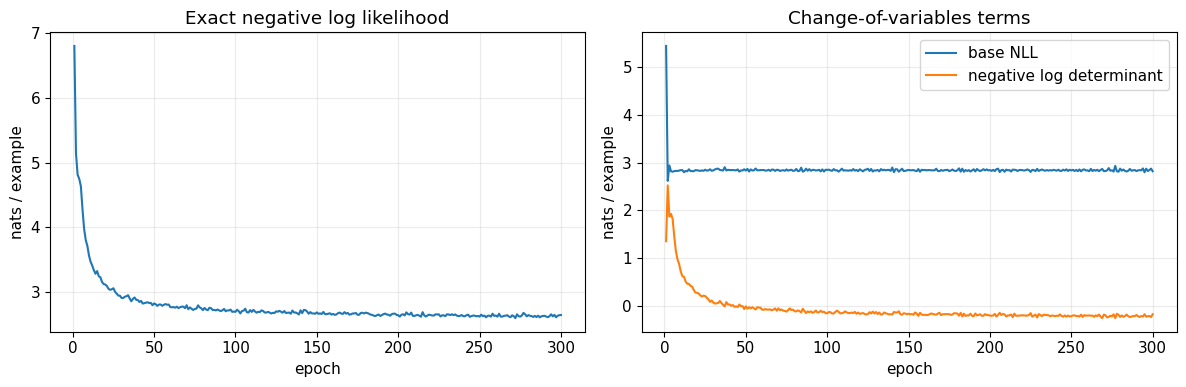

Train NLL: 2.594 nats | test NLL: 2.627 nats


In [6]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["nll"])
axes[0].set(
    xlabel="epoch", ylabel="nats / example", title="Exact negative log likelihood"
)
axes[1].plot(epochs, history["base_nll"], label="base NLL")
axes[1].plot(epochs, history["negative_log_det"], label="negative log determinant")
axes[1].set(xlabel="epoch", ylabel="nats / example", title="Change-of-variables terms")
axes[1].legend()
plt.tight_layout()
plt.show()

flow.eval()
with torch.no_grad():
    train_nll = -flow.log_prob(x_train.to(DEVICE)).mean().item()
    test_nll = -flow.log_prob(x_test.to(DEVICE)).mean().item()
print(f"Train NLL: {train_nll:.3f} nats | test NLL: {test_nll:.3f} nats")

## 7. Data transformed to the base space

A well-trained forward transformation should “Gaussianize” the data. Colors show original mixture identities, which were never used for training. The right panel compares transformed samples to the standard-normal density contours.

> **Predict before running.** After maximum-likelihood training, will the eight colored data modes remain eight separated clusters in base space, or be rearranged into an approximately standard-normal cloud? **Commit to a prediction and explain how invertibility constrains the rearrangement without fully preventing it.**

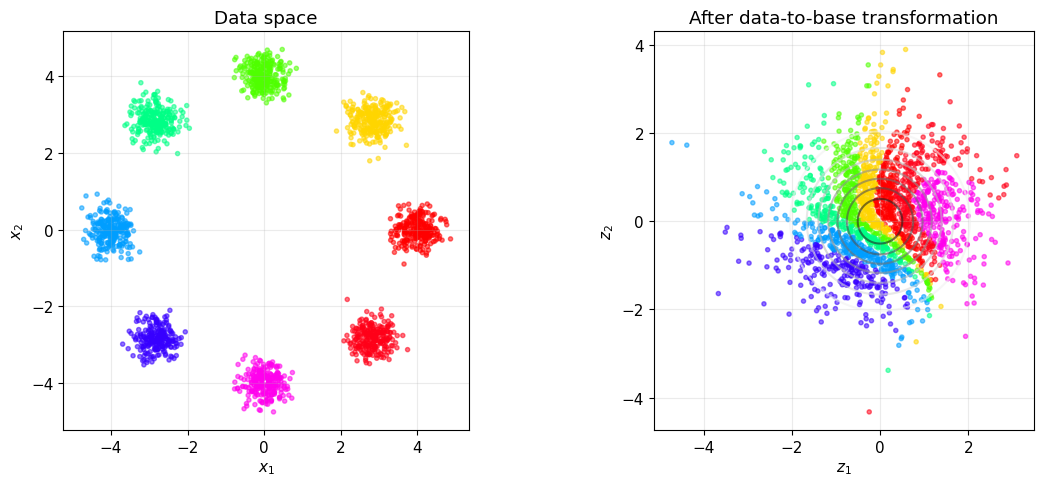

Transformed mean: [-0.036  0.103]
Transformed covariance:
[[1.035 0.027]
 [0.027 0.998]]


In [7]:
with torch.no_grad():
    z_test, test_log_det = flow(x_test.to(DEVICE))
z_test, test_log_det = z_test.cpu(), test_log_det.cpu()

axis = torch.linspace(-3.5, 3.5, 150)
g1, g2 = torch.meshgrid(axis, axis, indexing="xy")
normal_density = torch.exp(-0.5 * (g1**2 + g2**2)) / (2 * torch.pi)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(x_test[:, 0], x_test[:, 1], c=y_test, cmap="hsv", s=9, alpha=0.55)
axes[0].set(title="Data space", xlabel="$x_1$", ylabel="$x_2$")
axes[0].set_aspect("equal")
axes[1].contour(g1, g2, normal_density, levels=8, cmap="Greys", alpha=0.6)
axes[1].scatter(z_test[:, 0], z_test[:, 1], c=y_test, cmap="hsv", s=9, alpha=0.55)
axes[1].set(title="After data-to-base transformation", xlabel="$z_1$", ylabel="$z_2$")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()
print("Transformed mean:", z_test.mean(0).numpy().round(3))
print("Transformed covariance:")
print(torch.cov(z_test.T).numpy().round(3))

> **Expected observation / interpretation.** The transformed samples should collectively resemble the standard normal, while colors reveal how an invertible map interleaves and deforms the original components. Exact invertibility preserves individual points and neighborhoods, not the visual identity of eight separated clusters.

## 8. Sample from the model

Sampling runs the flow in reverse:

$$z\sim\mathcal N(0,I),\qquad x=f_\theta^{-1}(z).$$

Unlike the VAE, this flow has no separate observation-noise distribution: each base point maps deterministically to one data point.

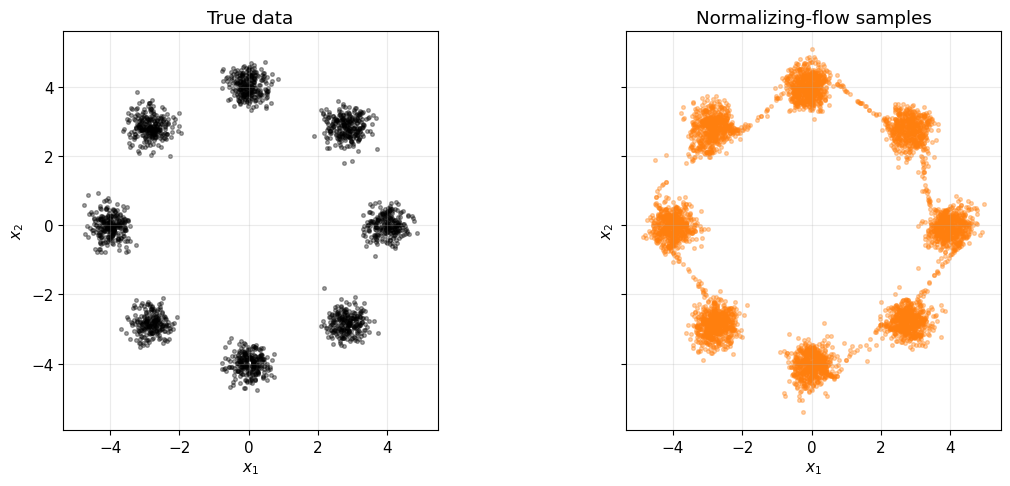

In [8]:
with torch.no_grad():
    generated = flow.sample(5_000).cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(x_test[:, 0], x_test[:, 1], s=7, alpha=0.35, color=PLOT_REFERENCE_COLOR)
axes[0].set_title("True data")
axes[1].scatter(generated[:, 0], generated[:, 1], s=7, alpha=0.35, color=PLOT_GENERATED_COLOR)
axes[1].set_title("Normalizing-flow samples")
for ax in axes:
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 9. Exact learned density

Because the model is invertible and has tractable Jacobian determinants, we can evaluate $p_\theta(x)$ exactly at arbitrary locations. This is a defining advantage over implicit models such as GANs.

The contour plot also exposes any probability “bridges” between modes that may be hard to notice in a finite sample.

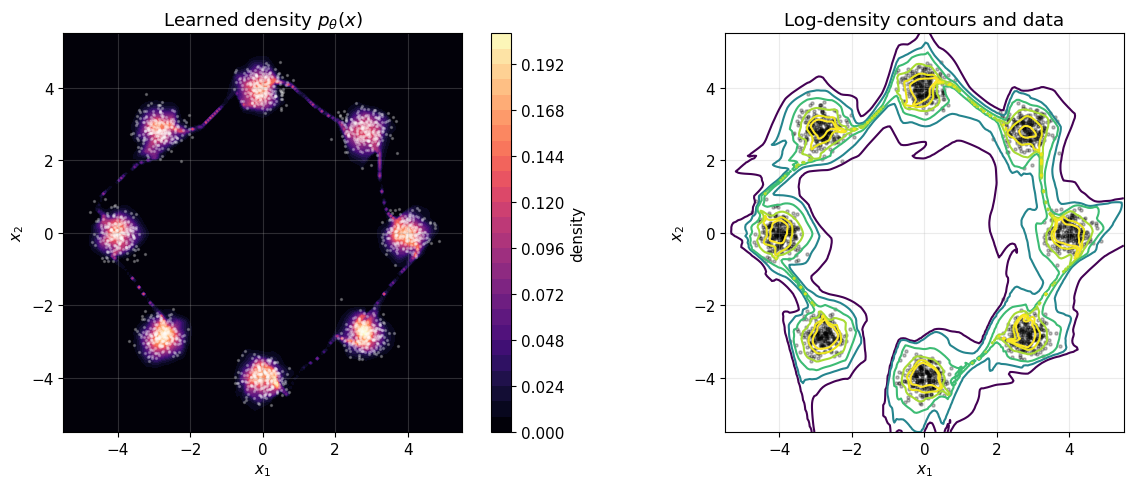

In [15]:
limit, resolution = 5.5, 180
x_axis = torch.linspace(-limit, limit, resolution)
xx, yy = torch.meshgrid(x_axis, x_axis, indexing="xy")
plot_grid = torch.stack([xx.ravel(), yy.ravel()], dim=1)

# Evaluate in chunks to keep memory use low.
log_prob_parts = []
with torch.no_grad():
    for chunk in plot_grid.split(4096):
        log_prob_parts.append(flow.log_prob(chunk.to(DEVICE)).cpu())
log_density = torch.cat(log_prob_parts).reshape(resolution, resolution)
density = log_density.exp()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
filled = axes[0].contourf(xx, yy, density, levels=30, cmap="magma")
axes[0].scatter(x_test[:, 0], x_test[:, 1], s=2, color="white", alpha=0.25)
axes[0].set(title="Learned density $p_\\theta(x)$", xlabel="$x_1$", ylabel="$x_2$")
fig.colorbar(filled, ax=axes[0], label="density")

levels = torch.quantile(
    log_density.ravel(), torch.tensor([0.60, 0.75, 0.85, 0.92, 0.96, 0.98])
).numpy()
axes[1].contour(xx, yy, log_density, levels=np.unique(levels), cmap="viridis")
axes[1].scatter(x_test[:, 0], x_test[:, 1], s=5, color=PLOT_REFERENCE_COLOR, alpha=0.25)
axes[1].set(title="Log-density contours and data", xlabel="$x_1$", ylabel="$x_2$")
for ax in axes:
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 10. Watch the transformation develop layer by layer

Each coupling layer makes a simple invertible deformation. Plotting intermediate states reveals how their composition turns disconnected-looking clusters into an approximately Gaussian cloud. The reverse sequence describes generation.

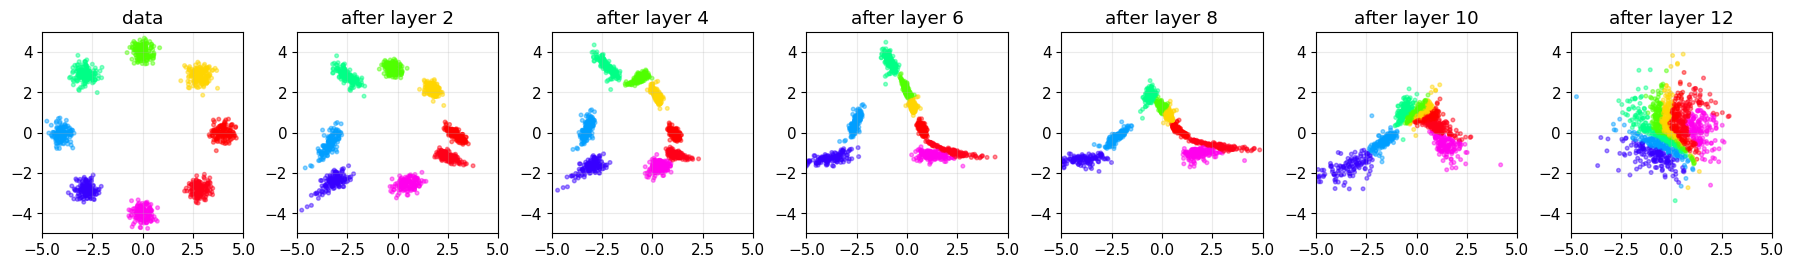

In [10]:
with torch.no_grad():
    states = [x_test[:1200].to(DEVICE)]
    current = states[0]
    for layer in flow.layers:
        current, _ = layer(current)
        states.append(current)

indices = [0, 2, 4, 6, 8, 10, 12]
fig, axes = plt.subplots(1, len(indices), figsize=(18, 3.6))
for ax, index in zip(axes, indices):
    points = states[index].cpu()
    ax.scatter(points[:, 0], points[:, 1], c=y_test[:1200], cmap="hsv", s=7, alpha=0.45)
    ax.set_xlim(-5.0, 5.0)
    ax.set_ylim(-5.0, 5.0)
    ax.set_title("data" if index == 0 else f"after layer {index}")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 11. Quantitative toy diagnostics

As in the VAE notebook, we measure nearest-mode frequencies, radial error, and the fraction of samples farther than three data standard deviations from every center. These are diagnostics, not universal evaluation metrics.

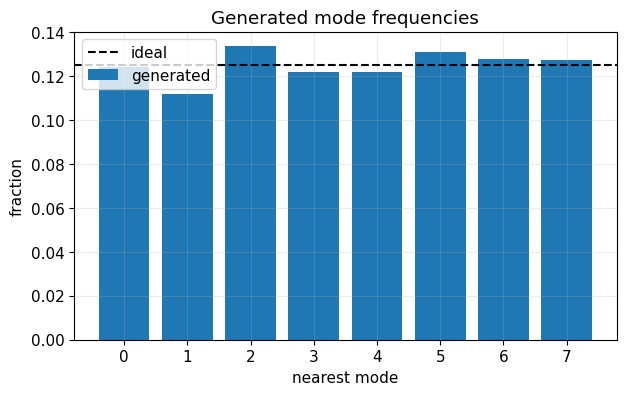

Mean absolute radial error: 0.264
Fraction >3σ from every mode: 4.3%
Modes receiving at least 1% of samples: 8/8


In [11]:
angles = 2 * torch.pi * torch.arange(N_MODES) / N_MODES
centers = RADIUS * torch.stack([torch.cos(angles), torch.sin(angles)], 1)
nearest_distance, nearest_mode = torch.cdist(generated, centers).min(1)
frequencies = torch.bincount(nearest_mode, minlength=N_MODES) / len(generated)
radial_error = (generated.norm(dim=1) - RADIUS).abs().mean()
gap_rate = (nearest_distance > 3 * DATA_STD).float().mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(N_MODES), frequencies.numpy(), label="generated")
ax.axhline(1 / N_MODES, color=PLOT_GUIDE_COLOR, linestyle="--", label="ideal")
ax.set(
    xlabel="nearest mode",
    ylabel="fraction",
    title="Generated mode frequencies",
    xticks=range(N_MODES),
)
ax.legend()
plt.show()
print(f"Mean absolute radial error: {radial_error:.3f}")
print(f"Fraction >3σ from every mode: {gap_rate:.1%}")
print(
    f"Modes receiving at least 1% of samples: {(frequencies > .01).sum().item()}/{N_MODES}"
)

## 12. Takeaways and homework experiments

### Takeaways
- A normalizing flow transforms a simple base density through an invertible map.
- Change of variables provides **exact likelihoods** and normalized densities.
- Affine coupling layers trade generality for a triangular, cheap Jacobian.
- Training and sampling use the same map in opposite directions.
- Unlike a VAE, there is no approximate posterior or ELBO.
- Invertibility requires data and latent dimensions to match in this basic construction.

### Important topological nuance

An invertible continuous map sends full-support densities to full-support densities. Therefore, a Gaussian-base flow cannot assign exactly zero density between separated modes. It can only make the connecting density very small.

### Mini-experiment 1 — Reduce the number of coupling layers
- **Hypothesis:** A shallower flow has insufficient compositional flexibility, leading to worse test NLL and more visible density bridges or mode-shape errors.
- **Metric/plot:** Compare exact test NLL, the learned-density contour, mode frequencies, radial error, and off-mode fraction across the baseline and one shallower model.
- **Controls:** Keep masks alternating, conditioner width, data, seed, optimizer, epochs, base distribution, and evaluation grid fixed.
- **Interpretation:** Worse NLL with localized contour errors indicates limited transformation capacity. A similar NLL with similar diagnostics suggests redundant depth.

### Mini-experiment 2 — Remove alternating masks
- **Hypothesis:** Reusing one mask leaves one coordinate unchanged by every coupling transform and sharply limits the learned joint deformation.
- **Metric/plot:** Inspect layer-by-layer transformations and exact-density contours. Compare test NLL and the variance/marginal shape of each transformed coordinate.
- **Controls:** Keep the number of layers and all conditioner/training settings fixed. Replace only the alternating-mask sequence with one repeated mask.
- **Interpretation:** A persistently unchanged coordinate and poor Gaussianization identify an architectural invertibility/expressivity limitation rather than an optimization failure.

### Extensions
- Remove the bounded log-scale and observe possible instability.
- Use additive coupling by forcing $s=0$. Volume cannot change.
- Compare exact test NLL and mode coverage with the VAE.
- Change the base distribution or increase the number of ring modes.

## Exit ticket

1. Write the log-density change-of-variables equation and identify the direction used for likelihood evaluation.
2. Why does affine coupling have a cheap Jacobian determinant, and why must masks alternate?
3. How can the same trained flow support exact density evaluation and generation, and what topological limitation remains for separated modes?

<details>
<summary><strong>Self-check answers</strong></summary>

1. $\log p_X(x)=\log p_Z(f_\theta(x))+\log|\det \partial f_\theta/\partial x|$. Likelihood uses the data-to-base direction.
2. Its Jacobian is triangular, so the log-determinant is the sum of log-scales. Alternating masks lets every coordinate be transformed and condition later transformations.
3. Evaluate density with the forward map and sample with its explicit inverse. A continuous invertible transformation of a full-support Gaussian still has full support, so connecting density can become tiny but not exactly zero.

</details>

## References and further reading

- [Dinh, Sohl-Dickstein & Bengio, *Density Estimation Using Real NVP* (ICLR 2017)](https://openreview.net/forum?id=HkpbnH9lx): Introduces the affine-coupling architecture and exact change-of-variables training used here.
- [Papamakarios et al., *Normalizing Flows for Probabilistic Modeling and Inference* (JMLR 2021)](https://jmlr.org/papers/v22/19-1028.html): Provides a broad, accessible review of flow constructions, expressivity, and applications.